# Week 1 - Linear Regression

## Introduction

Examine linear regression, polynomials, interactions, and multicollinearity. Model performance will be evaluated to determine which techniques are appropriate for each dataset.

### Datasets
1. Predict Conversion in Digital Marketing Dataset
2. Marketing and Product Performance
3. Companies

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")

In [ ]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing Dataset:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Companies: (734, 19)


In [ ]:
#structure of each dataset
for name, df in [
    ("Digital Marketing Campaign", df1),
    ("Marketing and Product Performance", df2),
    ("Synthetic B2B CRM & Marketing Dataset", df3)
]:
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    print("Missing values:", df.isnull().sum().sum())
    display(df.head())


Digital Marketing Campaign
Columns: ['CustomerID', 'Age', 'Gender', 'Income', 'CampaignChannel', 'CampaignType', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints', 'AdvertisingPlatform', 'AdvertisingTool', 'Conversion']
Missing values: 0


,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1



Marketing and Product Performance
Columns: ['Campaign_ID', 'Product_ID', 'Budget', 'Clicks', 'Conversions', 'Revenue_Generated', 'ROI', 'Customer_ID', 'Subscription_Tier', 'Subscription_Length', 'Flash_Sale_ID', 'Discount_Level', 'Units_Sold', 'Bundle_ID', 'Bundle_Price', 'Customer_Satisfaction_Post_Refund', 'Common_Keywords']
Missing values: 0


,Campaign_ID,Product_ID,Budget,Clicks,Conversions,Revenue_Generated,ROI,Customer_ID,Subscription_Tier,Subscription_Length,Flash_Sale_ID,Discount_Level,Units_Sold,Bundle_ID,Bundle_Price,Customer_Satisfaction_Post_Refund,Common_Keywords
0,CMP_RLSDVN,PROD_HBJFA3,41770.45,4946,73,15520.09,1.94,CUST_1K7G39,Premium,4,FLASH_1VFK5K,43,34,BNDL_29U6W5,433.80,4,Affordable
1,CMP_JHHUE9,PROD_OE8YNJ,29900.93,570,510,30866.17,0.76,CUST_0DWS6F,Premium,4,FLASH_1M6COK,28,97,BNDL_ULV60J,289.29,2,Innovative
2,CMP_6SBOWN,PROD_4V8A08,22367.45,3546,265,32585.62,1.41,CUST_BR2GST,Basic,9,FLASH_J4PEON,51,160,BNDL_0HY0EF,462.87,4,Affordable
3,CMP_Q31QCU,PROD_A1Q6ZB,29957.54,2573,781,95740.12,3.32,CUST_6TBY6K,Premium,32,FLASH_1TOVXT,36,159,BNDL_AI09BC,334.16,1,Durable
4,CMP_AY0UTJ,PROD_F57N66,36277.19,818,79,81990.43,3.53,CUST_XASI45,Standard,29,FLASH_AOBHXL,20,52,BNDL_R03ITT,371.67,2,Affordable



Companies
Columns: ['Company_ID', 'Industry', 'Company_Size', 'Annual_Revenue (M₺)', 'Marketing_Spend (K₺)', 'Campaign_Type', 'Leads_Generated', 'Conversion_Rate (%)', 'Region', 'District', 'Last_Product_1', 'Last_Product_2', 'Frequency_of_Purchase', 'Days_Since_Last_Purchase', 'Contract_Status', 'Total_Purchases_Last_Year', 'Payment_Behavior', 'Preferred_Channel', 'Sales_Rep']
Missing values: 0


,Company_ID,Industry,Company_Size,Annual_Revenue (M₺),Marketing_Spend (K₺),Campaign_Type,Leads_Generated,Conversion_Rate (%),Region,District,Last_Product_1,Last_Product_2,Frequency_of_Purchase,Days_Since_Last_Purchase,Contract_Status,Total_Purchases_Last_Year,Payment_Behavior,Preferred_Channel,Sales_Rep
0,C0001,"Mining, metals & minerals",Medium,17.3,33,SEM,12,0.9,Adana,Ceyhan,Process safety & automation,Valves,Monthly,6,Pending,15,On-time,Sales Rep,E**** T*******
1,C0002,Space,Small,4.9,12,Content Marketing,4,1.2,Sakarya,Arifiye,Energy storage systems,Actuators & motion control,Occasionally,310,Active,0,On-time,Sales Rep,D**** S*******
2,C0003,Buildings,Small,1.1,11,Content Marketing,9,1.1,Ankara,Etimesgut,Lighting & controls,Conduit & cable management,Quarterly,63,Active,4,Occasional delay,Sales Rep,B**** K*******
3,C0004,Oil & gas,Small,5.7,29,Trade Show,9,0.4,Eskisehir,Tepebasi,Medium-voltage power systems,Process safety & automation,Monthly,17,Active,8,On-time,Sales Rep,A**** Y*******
4,C0005,Oil & gas,Small,8.3,23,Trade Show,11,0.5,Zonguldak,Kozlu,Medium-voltage power systems,Fuel systems & emissions,Quarterly,93,Active,3,On-time,Sales Rep,C**** D*******



## Data Quality and Preprocessing

Before performing regression analysis, each dataset will be examined for missing values, duplicate records, blank entries, and data types. This will help identify any necessary preprocessing steps.


In [ ]:
datasets = {
    "Digital Marketing Campaign": df1,
    "Marketing and Product Performance": df2,
    "Companies": df3
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isnull().sum().sum())

    # Check for empty or whitespace-only cells
    blank_cells = df.select_dtypes(include="object").apply(
        lambda col: col.str.strip().eq("").sum()
    )
    print("Blank cells:", blank_cells.sum())

    print("\nData types:")
    print(df.dtypes)
    print("-" * 50)


Digital Marketing Campaign
Duplicate rows: 0
Missing values: 0
Blank cells: 0

Data types:
CustomerID               int64
Age                      int64
Gender                  object
Income                   int64
CampaignChannel         object
CampaignType            object
AdSpend                float64
ClickThroughRate       float64
ConversionRate         float64
WebsiteVisits            int64
PagesPerVisit          float64
TimeOnSite             float64
SocialShares             int64
EmailOpens               int64
EmailClicks              int64
PreviousPurchases        int64
LoyaltyPoints            int64
AdvertisingPlatform     object
AdvertisingTool         object
Conversion               int64
dtype: object
--------------------------------------------------

Marketing and Product Performance
Duplicate rows: 0
Missing values: 0
Blank cells: 0

Data types:
Campaign_ID                           object
Product_ID                            object
Budget                            


## Exploratory Data Analysis

Correlation heatmaps will be used to examine relationships between numerical variables across all three datasets. These visualizations will help identify potential predictors for regression analysis and highlight possible multicollinearity.


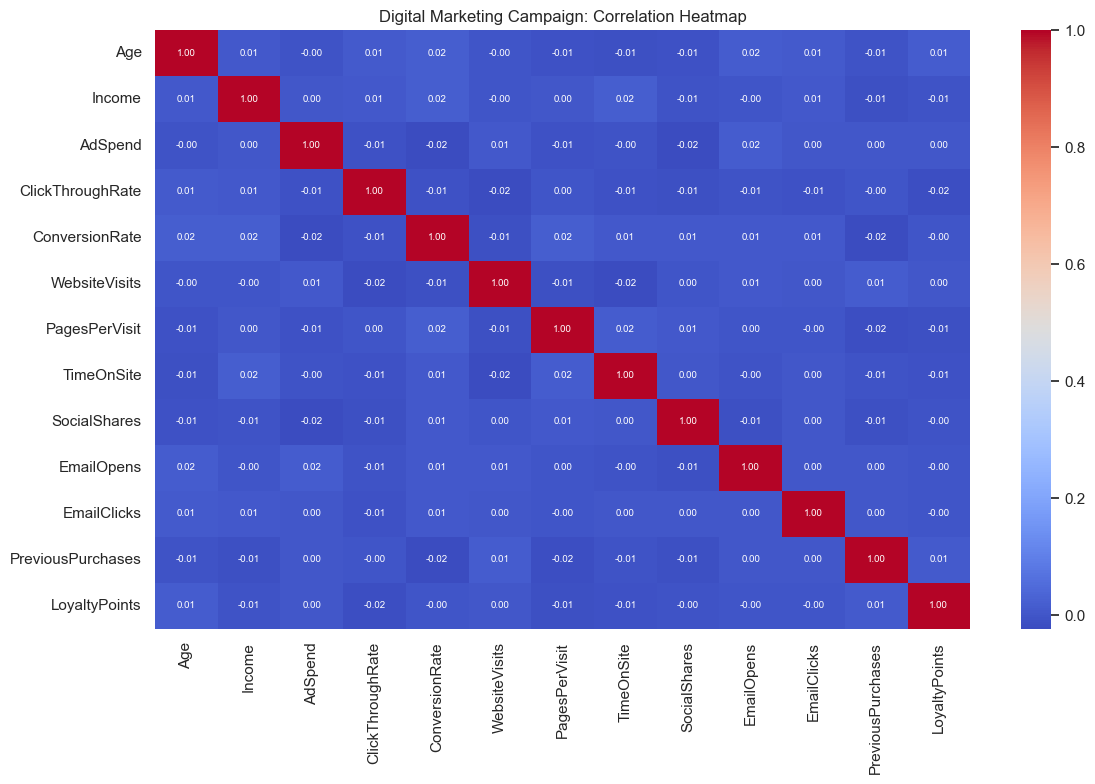

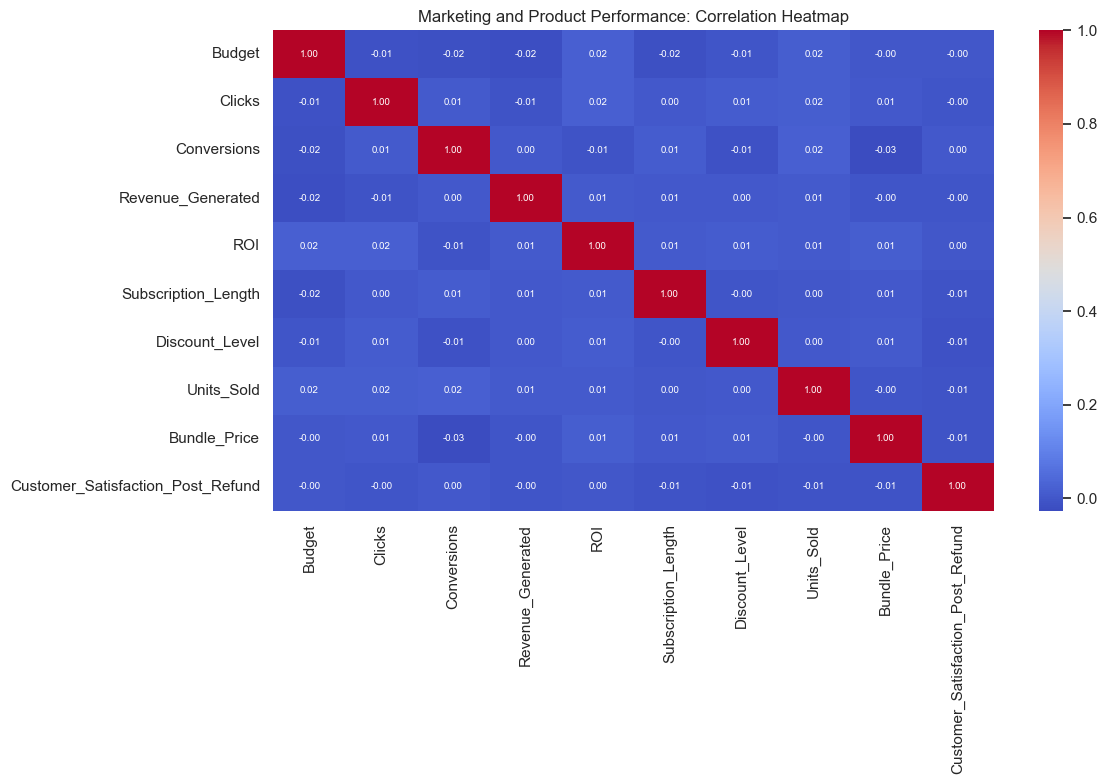

/Users/staghetti/Library/Python/3.9/lib/python/site-packages/seaborn/utils.py:61: UserWarning: Glyph 8378 (\N{TURKISH LIRA SIGN}) missing from font(s) Arial.
  fig.canvas.draw()
/Users/staghetti/Library/Python/3.9/lib/python/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8378 (\N{TURKISH LIRA SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


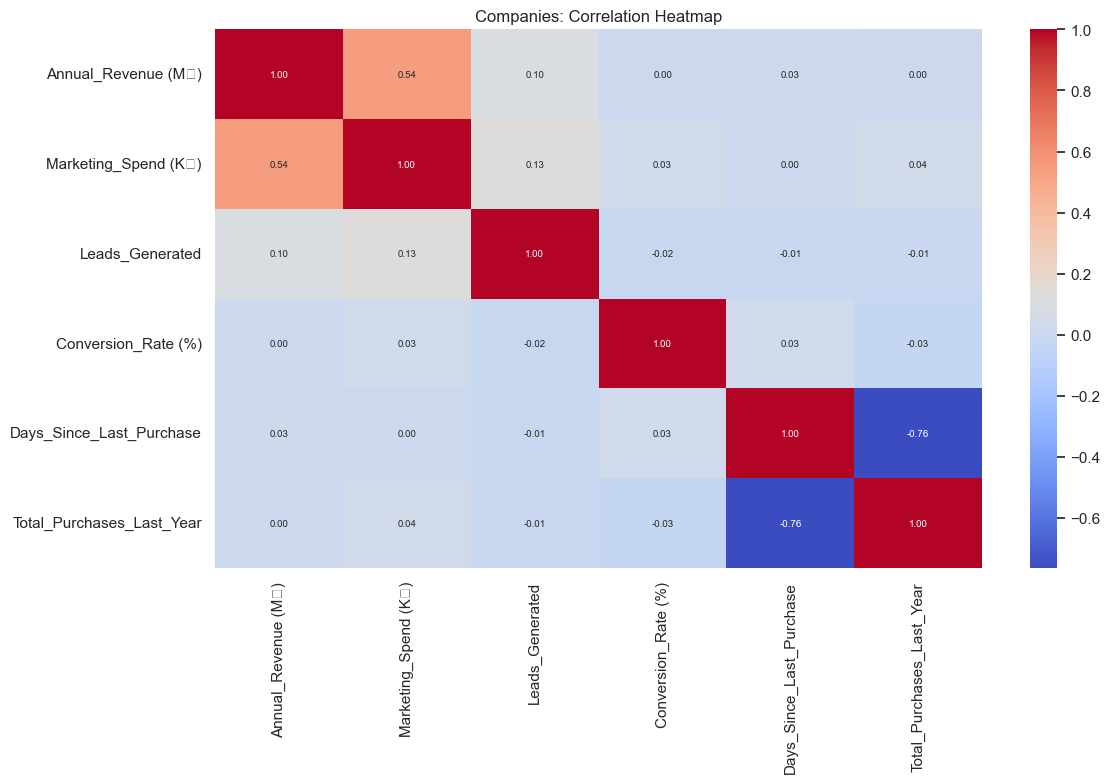

In [ ]:
#correlation heatmaps for all three datasets
for name, df in datasets.items():
    numeric_df = df.select_dtypes(include="number").copy()

    # Remove identification columns and binary outcomes
    numeric_df = numeric_df.drop(
        columns=["CustomerID", "Conversion"],
        errors="ignore"
    )

    plt.figure(figsize=(12, 8))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        annot_kws={"size": 7}
    )
    plt.title(f"{name}: Correlation Heatmap")
    plt.tight_layout()
    plt.show()

The correlation heatmaps revealed different patterns across the three datasets. The Digital Marketing Campaign and Marketing and Product Performance datasets showed very weak linear correlations between their numerical variables. This suggests that simple linear relationships may have limited predictive value. The Companies dataset showed stronger relationships. Annual revenue and marketing spend had a moderate positive correlation (0.54), while days since last purchase and total purchases last year had a strong negative correlation (-0.76). These findings provide a starting point for testing linear regression, polynomial terms, and interaction effects. Multicollinearity will also be investigated using variance inflation factors (VIF).

In [ ]:
#select predictors and target
features = [
    "AdSpend",
    "ClickThroughRate",
    "WebsiteVisits",
    "TimeOnSite",
    "EmailClicks"
]

X = df1[features]
y = df1["ConversionRate"]

#split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# train the baseline model
model = LinearRegression()
model.fit(X_train, y_train)

# evaluate on unseen testing data
y_pred = model.predict(X_test)

print("Training R²:", round(model.score(X_train, y_train), 4))
print("Testing R²:", round(r2_score(y_test, y_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))

Training R²: 0.0007
Testing R²: -0.0009
Testing RMSE: 0.0541


The baseline linear regression model produced a training R² of 0.0007 and a testing R² of -0.0009, indicating very limited predictive performance. The testing RMSE was 0.0541. These findings are consistent with the weak correlations observed during exploratory analysis. The selected predictors do not explain much of the variation in conversion rate through a linear relationship.

In [9]:

# Create polynomial and interaction features
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Train polynomial regression model
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# Evaluate model
poly_train_r2 = poly_model.score(X_train_poly, y_train)
poly_pred = poly_model.predict(X_test_poly)

poly_test_r2 = r2_score(y_test, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))

print("Polynomial features:", X_train_poly.shape[1])
print("Training R²:", round(poly_train_r2, 4))
print("Testing R²:", round(poly_test_r2, 4))
print("Testing RMSE:", round(poly_rmse, 4))


Polynomial features: 20
Training R²: 0.0047
Testing R²: -0.0047
Testing RMSE: 0.0542


Polynomial regression increased the number of features from 5 to 20. While there was an increase in training R² from 0.0007 to 0.0047, testing R² fell from -0.0009 to -0.0047. Testing RMSE increased from 0.0541 to 0.0542. These results suggest that adding polynomial and interaction terms did not improve predictive performance and may have introduced mild overfitting.

In [ ]:
# interaction terms without squared features
interaction = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_train_int = interaction.fit_transform(X_train)
X_test_int = interaction.transform(X_test)

#train interaction model
interaction_model = LinearRegression()
interaction_model.fit(X_train_int, y_train)

#eval performance
int_train_r2 = interaction_model.score(X_train_int, y_train)
int_pred = interaction_model.predict(X_test_int)
int_test_r2 = r2_score(y_test, int_pred)
int_rmse = np.sqrt(mean_squared_error(y_test, int_pred))

print("Interaction features:", X_train_int.shape[1])
print("Training R²:", round(int_train_r2, 4))
print("Testing R²:", round(int_test_r2, 4))
print("Testing RMSE:", round(int_rmse, 4))

Interaction features: 15
Training R²: 0.0027
Testing R²: -0.0014
Testing RMSE: 0.0541


The interaction model generated 15 features and achieved a training R² of 0.0027 and a testing R² of -0.0014. Although the interaction model performed slightly better than polynomial regression, it did not outperform the baseline linear regression model. Overall, the additional interaction and polynomial terms did not meaningfully improve predictions of conversion rate.

In [ ]:
#calculating VIF for the original predictors
from statsmodels.tools.tools import add_constant

X_vif = add_constant(X_train)
vif_data = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})
#excluding the intercept from interpretation
vif_data = vif_data[vif_data["Feature"] != "const"]
print(vif_data.round(3).to_string(index=False))

         Feature   VIF
         AdSpend 1.001
ClickThroughRate 1.001
   WebsiteVisits 1.001
      TimeOnSite 1.001
     EmailClicks 1.000


The VIF analysis produced values between 1.000 and 1.001 for all five predictors, indicating minimal multicollinearity. This suggests that the poor regression performance is not caused by multicollinearity among the selected predictors. Instead, these variables appear to have limited predictive value for conversion rate in the models tested.

In [ ]:
#add categorical predictors to the original features
features_cat = features + [
    "CampaignChannel",
    "CampaignType"
]
X_cat = pd.get_dummies(
    df1[features_cat],
    columns=["CampaignChannel", "CampaignType"],
    drop_first=True,
    dtype=int
)

#train/test split
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X_cat,
    y,
    test_size=0.2,
    random_state=42
)
#train and eval
cat_model = LinearRegression()
cat_model.fit(X_train_cat, y_train_cat)
cat_pred = cat_model.predict(X_test_cat)

print("Total features:", X_cat.shape[1])
print("Training R²:", round(cat_model.score(X_train_cat, y_train_cat), 4))
print("Testing R²:", round(r2_score(y_test_cat, cat_pred), 4))
print("Testing RMSE:", round(
    np.sqrt(mean_squared_error(y_test_cat, cat_pred)), 4
))

Total features: 12
Training R²: 0.002
Testing R²: -0.0048
Testing RMSE: 0.0542


### Digital Marketing Campaign: Conclusion

The regression analysis investigated whether advertising spend, customer engagement, and campaign characteristics could predict conversion rate. The baseline linear regression model achieved a testing R² of -0.0009. Adding polynomial terms, interaction terms, and categorical predictors did not improve performance. VIF values between 1.000 and 1.001 indicated minimal multicollinearity among the original numerical predictors. Overall, the selected predictors demonstrated limited predictive value for conversion rate. The additional model complexity did not improve performance on the testing data.


## Dataset 2: Marketing and Product Performance

This analysis investigates whether marketing activities and product performance metrics can predict revenue generated. Linear regression, polynomial regression, interaction terms, and multicollinearity analysis will be used to evaluate relationships between the selected variables.

In [ ]:
features2 = [
    "Budget",
    "Clicks",
    "Conversions",
    "Units_Sold",
    "Bundle_Price"
]
X2 = df2[features2]
y2 = df2["Revenue_Generated"]

#splitting data
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

#train baseline linear regression
model2 = LinearRegression()
model2.fit(X2_train, y2_train)
#eval
y2_pred = model2.predict(X2_test)

print("Training R²:", round(model2.score(X2_train, y2_train), 4))
print("Testing R²:", round(r2_score(y2_test, y2_pred), 4))
print("Testing RMSE:", round(
    np.sqrt(mean_squared_error(y2_test, y2_pred)), 4
))

Training R²: 0.0007
Testing R²: -0.0012
Testing RMSE: 28572.378


The baseline linear regression model achieved a training R² of 0.0007 and a testing R² of -0.0012, with a testing RMSE of 28,572.378. These results indicate that the selected marketing and product performance variables have very limited linear predictive value for revenue generated.


In [ ]:
# Create polynomial features
poly2 = PolynomialFeatures(degree=2, include_bias=False)

X2_train_poly = poly2.fit_transform(X2_train)
X2_test_poly = poly2.transform(X2_test)

# Train polynomial regression
poly_model2 = LinearRegression()
poly_model2.fit(X2_train_poly, y2_train)

# Evaluate
poly2_pred = poly_model2.predict(X2_test_poly)

print("Polynomial features:", X2_train_poly.shape[1])
print("Training R²:", round(poly_model2.score(X2_train_poly, y2_train), 4))
print("Testing R²:", round(r2_score(y2_test, poly2_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y2_test, poly2_pred)), 4))

Polynomial features: 20
Training R²: 0.0022
Testing R²: -0.0036
Testing RMSE: 28606.4773


Polynomial regression increased the number of features from 5 to 20. Training R² improved slightly from 0.0007 to 0.0022, but testing R² decreased from -0.0012 to -0.0036. Testing RMSE also increased from 28,572.378 to 28,606.4773. These findings suggest that adding polynomial and interaction terms did not improve revenue predictions and may have introduced mild overfitting.


In [ ]:
interaction2 = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X2_train_int = interaction2.fit_transform(X2_train)
X2_test_int = interaction2.transform(X2_test)

# Train interaction model
interaction_model2 = LinearRegression()
interaction_model2.fit(X2_train_int, y2_train)

# Evaluate performance
int2_pred = interaction_model2.predict(X2_test_int)

print("Interaction features:", X2_train_int.shape[1])
print("Training R²:", round(interaction_model2.score(X2_train_int, y2_train), 4))
print("Testing R²:", round(r2_score(y2_test, int2_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y2_test, int2_pred)), 4))

Interaction features: 15
Training R²: 0.0019
Testing R²: -0.0025
Testing RMSE: 28591.9141


The interaction model generated 15 features and achieved a training R² of 0.0019 and a testing R² of -0.0025. Although the interaction model performed slightly better than polynomial regression, it did not outperform the baseline linear regression model. Overall, adding polynomial and interaction terms did not improve revenue predictions. The more complex models showed slightly worse performance on the testing data.


In [ ]:
#calculating VIF
X2_vif = add_constant(X2_train)
vif_data2 = pd.DataFrame({
    "Feature": X2_vif.columns,
    "VIF": [
        variance_inflation_factor(X2_vif.values, i)
        for i in range(X2_vif.shape[1])
    ]
})

# Exclude the intercept
vif_data2 = vif_data2[vif_data2["Feature"] != "const"]
print(vif_data2.round(3).to_string(index=False))

     Feature   VIF
      Budget 1.001
      Clicks 1.001
 Conversions 1.001
  Units_Sold 1.001
Bundle_Price 1.000


The VIF analysis produced values between 1.000 and 1.001 for all five predictors, indicating minimal multicollinearity. This suggests that the poor regression performance is not caused by multicollinearity among the selected predictors. The variables showed limited predictive value for revenue in the models tested.


In [ ]:
#categorical variables
features2_cat = features2 + [
    "Subscription_Tier",
    "Common_Keywords"
]

X2_cat = pd.get_dummies(df2[features2_cat],columns=["Subscription_Tier", "Common_Keywords"],drop_first=True,dtype=int)

# split the data
X2_cat_train, X2_cat_test, y2_cat_train, y2_cat_test = train_test_split(
    X2_cat, y2,
    test_size=0.2,
    random_state=42
)

# train the model
cat_model2 = LinearRegression()
cat_model2.fit(X2_cat_train, y2_cat_train)

# evaluate
cat2_pred = cat_model2.predict(X2_cat_test)

print("Total features:", X2_cat.shape[1])
print("Training R²:", round(cat_model2.score(X2_cat_train, y2_cat_train), 4))
print("Testing R²:", round(r2_score(y2_cat_test, cat2_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y2_cat_test, cat2_pred)), 4))

Total features: 10
Training R²: 0.0016
Testing R²: -0.0002
Testing RMSE: 28558.4868



### Marketing and Product Performance: Conclusion

The analysis investigated whether marketing budget, clicks, conversions, product sales, and other characteristics could predict revenue generated. The baseline model achieved a testing R² of -0.0012. Adding polynomial and interaction terms reduced testing performance, while including categorical variables produced a slight improvement, achieving a testing R² of -0.0002. VIF values ranging from 1.000 to 1.001 represented very low multicollinearity within the original variables. In general, all of the models lacked significant predictive power. The results suggest that the selected variables provide limited information for predicting revenue in this dataset.


## Dataset 3: Synthetic B2B CRM & Marketing Dataset

This analysis investigates whether company revenue, marketing spending, and purchasing behavior can predict the number of leads generated. Linear regression, polynomial regression, interaction terms, and multicollinearity analysis will be used to evaluate the selected predictors.

In [ ]:
# predictors and target
features3 = [
    "Annual_Revenue (M₺)",
    "Marketing_Spend (K₺)",
    "Days_Since_Last_Purchase",
    "Total_Purchases_Last_Year"
]

X3 = df3[features3]
y3 = df3["Leads_Generated"]

# spltting data
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42)

# train baseline regression
model3 = LinearRegression()
model3.fit(X3_train, y3_train)

# eval 
y3_pred = model3.predict(X3_test)

print("Training R²:", round(model3.score(X3_train, y3_train), 4))
print("Testing R²:", round(r2_score(y3_test, y3_pred), 4))
print("Testing RMSE:", round(
    np.sqrt(mean_squared_error(y3_test, y3_pred)), 4
))

Training R²: 0.0232
Testing R²: -0.0218
Testing RMSE: 3.0941


The baseline linear regression model achieved a training R² of 0.0232 and a testing R² of -0.0218, with a testing RMSE of 3.0941. Although the model explained approximately 2.32% of the variation in the training data, it performed poorly on the testing data. These findings indicate that the selected variables have limited predictive value for leads generated.

In [ ]:
# polynomial features
poly3 = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X3_train_poly = poly3.fit_transform(X3_train)
X3_test_poly = poly3.transform(X3_test)

# Train polynomial regression
poly_model3 = LinearRegression()
poly_model3.fit(X3_train_poly, y3_train)
# Evaluate performance
poly3_pred = poly_model3.predict(X3_test_poly)

print("Polynomial features:", X3_train_poly.shape[1])
print("Training R²:", round(poly_model3.score(X3_train_poly, y3_train), 4))
print("Testing R²:", round(r2_score(y3_test, poly3_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y3_test, poly3_pred)), 4))

Polynomial features: 14
Training R²: 0.0398
Testing R²: -0.0548
Testing RMSE: 3.1437


Polynomial regression increased the number of features from 4 to 14. The training R² value went up from 0.0232 to 0.0398; however, the testing R² value went down from -0.0218 to -0.0548. The testing RMSE value went up from 3.0941 to 3.1437. It seems that the model became more complicated but not more accurate.

In [ ]:
#interaction terms
interaction3 = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X3_train_int = interaction3.fit_transform(X3_train)
X3_test_int = interaction3.transform(X3_test)

# train interaction model
interaction_model3 = LinearRegression()
interaction_model3.fit(X3_train_int, y3_train)
# evaluate performance
int3_pred = interaction_model3.predict(X3_test_int)

print("Interaction features:", X3_train_int.shape[1])
print("Training R²:", round(interaction_model3.score(X3_train_int, y3_train), 4))
print("Testing R²:", round(r2_score(y3_test, int3_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y3_test, int3_pred)), 4))

Interaction features: 10
Training R²: 0.0287
Testing R²: -0.0306
Testing RMSE: 3.1074


The interaction model generated 10 features and achieved a training R² of 0.0287 and a testing R² of -0.0306. Although it performed slightly better than polynomial regression, it did not outperform the baseline linear regression model. Overall, the additional polynomial and interaction terms increased model complexity without improving predictions of leads generated.

In [ ]:
X3_vif = add_constant(X3_train)

vif_data3 = pd.DataFrame({
    "Feature": X3_vif.columns,
    "VIF": [
        variance_inflation_factor(X3_vif.values, i)
        for i in range(X3_vif.shape[1])
    ]
})

# exclude intercept
vif_data3 = vif_data3[
    vif_data3["Feature"] != "const"
]
print(vif_data3.round(3).to_string(index=False))

                  Feature   VIF
      Annual_Revenue (M₺) 1.400
     Marketing_Spend (K₺) 1.402
 Days_Since_Last_Purchase 2.407
Total_Purchases_Last_Year 2.409


The VIF analysis produced values ranging from 1.400 to 2.409. Days since last purchase and total purchases last year had the highest values, indicating some shared information between these predictors. However, all VIF values were below 5, suggesting that multicollinearity is not a major concern among the selected variables.

In [ ]:
#categorical variables
features3_cat = features3 + [
    "Company_Size",
    "Campaign_Type"
]

# convert categories into numerical indicators
X3_cat = pd.get_dummies(
    df3[features3_cat],
    columns=["Company_Size", "Campaign_Type"],
    drop_first=True,
    dtype=int
)

# splitting training and testing data
X3_cat_train, X3_cat_test, y3_cat_train, y3_cat_test = train_test_split(
    X3_cat, y3,
    test_size=0.2,
    random_state=42
)

# train regression model
cat_model3 = LinearRegression()
cat_model3.fit(X3_cat_train, y3_cat_train)
# evaluate
cat3_pred = cat_model3.predict(X3_cat_test)

print("Total features:", X3_cat.shape[1])
print("Training R²:", round(cat_model3.score(X3_cat_train, y3_cat_train), 4))
print("Testing R²:", round(r2_score(y3_cat_test, cat3_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y3_cat_test, cat3_pred)), 4))

Total features: 11
Training R²: 0.0354
Testing R²: -0.0388
Testing RMSE: 3.1197


### B2B Dataset: Conclusion

The study assessed the possibility of using company revenue, expenditure on marketing activities, purchasing behavior, and features of marketing campaigns to forecast the number of leads that a firm receives. The base linear regression had a testing R² value of -0.0218. The introduction of polynomial variables, interaction variables, and categorical variables led to decreased performance during testing. The VIFs varied between 1.400 and 2.409, showing the presence of collinearity, but not of serious multicollinearity. Overall, none of the models showed any significant predictive performance.

## Week 1: Overall Findings

This week's analysis applied linear regression, polynomial regression, interaction terms, and multicollinearity testing to three digital marketing datasets. Across all three datasets, the models demonstrated limited predictive performance, with negative testing R² values. Polynomial and interaction terms generally improved training performance but reduced testing performance, suggesting that additional complexity did not help the models generalize. VIF analysis found minimal multicollinearity in the first two datasets and some correlation among predictors in the Companies dataset, although none of the VIF values indicated serious multicollinearity. Categorical features added a little value to the Marketing and Product Performance data set, although it was negligible in terms of predictions. Generally, these findings show the significance of testing models on data that they have not yet seen before.